# PROYECTO PTIA 2026-2
## StudyFlow AI: red neuronal que prioriza y reparte el trabajo

**Integrantes:**

Karol Ximena Rodriguez Reyes
Juan David Moreno D'Aleman

---

### ¿Qué vamos a hacer en este notebook?

StudyFlow AI genera horarios de estudio. El sistema completo tiene cuatro piezas:

`LLM (entiende lo que pide el estudiante)` -> `Validador (¿cabe en el tiempo?)` -> **`MLP (prioriza y reparte)`** -> `Capa de asignación (arma las sesiones)`

Aquí trabajamos **solo el MLP**, que es el componente principal del proyecto, explicando qué se hace, cómo y por qué, y con gráficas para ver el avance.



# PASO 1. DEFINIR EL PROBLEMA

**¿Qué tiene que hacer la red?** Recibe **una actividad** del estudiante y responde dos cosas:

* **Salida A, prioridad:** un número entre 0 y 1 (qué tan urgente es). Sirve para ordenar las actividades.
* **Salida B, reparto:** tres proporciones que suman 1 (cuánto trabajo va al *inicio*, al *medio* y al *final* del tiempo disponible). Por ejemplo `[0.5, 0.3, 0.2]` significa "adelanta el trabajo".

**¿Con qué información?** Seis características por actividad, todas escaladas a [-1, 1]:

| # | Característica | Qué es |
|---|---|---|
| 1 | `x_dias` | Días que faltan para la fecha límite (1 a 30) |
| 2 | `x_prioridad` | Prioridad que puso el estudiante (baja = -1, media = 0, alta = 1) |
| 3 | `x_dificultad` | Dificultad (baja = -1, media = 0, alta = 1) |
| 4 | `x_horas` | Horas estimadas de trabajo (1 a 20) |
| 5 | `x_ventana` | Horas libres que tiene el estudiante hasta esa fecha límite |
| 6 | `x_carga` | **Carga relativa:** horas que vencen hasta esa fecha / horas libres hasta esa fecha (0 a 1) |

La carga relativa le da a la red el contexto de *todas* las actividades del estudiante, aunque la red mire una actividad a la vez.

**¿Por qué una sola red con dos salidas (multitarea)?** Porque las dos decisiones dependen de la misma información. Las capas ocultas se comparten y al final la red se bifurca: una neurona con **sigmoide** para la prioridad y tres neuronas con **softmax** para el reparto (así suman 1 siempre).

**¿Cómo sabemos si funciona?** Con los objetivos del documento del proyecto:

| Salida | Métrica | Objetivo |
|---|---|---|
| A, prioridad | Correlación de **Spearman** con la prioridad del profesor | ≥ 0.90 |
| B, reparto | Error absoluto medio (**MAE**) por tramo | ≤ 0.05 |

* **Spearman** mide si la red ordena las actividades igual que la referencia. Importa el orden, no el valor exacto.
* **MAE** es el error promedio entre la proporción predicha y la real, en cada tramo.

**¿Cómo sabemos si la red aporta algo?** Con dos **líneas base** que calcularemos en el Paso 2: (1) predecir siempre el promedio y (2) una regresión lineal. Si la red no las mejora, no se justifica.

# PASO 2. EXPLORAR Y PREPARAR LOS DATOS

## 2.1 ¿De dónde salen los datos?

No existe un dataset público de "actividades con su horario ideal", así que **lo generamos** (script `generar_dataset.py`):

1. Se crean **3000 escenarios**. Cada uno es un estudiante con entre **3 y 8 actividades** y entre **2 y 8 horas libres por día** durante 30 días.
2. Un **validador de factibilidad** descarta los escenarios imposibles: para cada fecha límite, las horas de trabajo que vencen hasta ese día deben caber en las horas libres hasta ese día. Se aceptó el 67.5 % de los escenarios generados.
3. Un **profesor heurístico** (reglas que escribimos nosotros) etiqueta cada actividad con su prioridad y su reparto. A la prioridad se le suma un poco de ruido (σ = 0.02).
4. Los escenarios se dividen **70 % entrenamiento / 15 % validación / 15 % prueba**, y la división es **por escenario completo, no por actividad**. Así evitamos que actividades de un mismo estudiante queden en entrenamiento y en prueba a la vez, porque su carga relativa depende de las demás.

## 2.2 Cargar los datos

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

azul, naranja, celeste = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True, "font.size": 10})

df = pd.read_csv("../data/dataset_studyflow.csv")
print("Actividades (filas):", len(df), ", Escenarios:", df["escenario_id"].nunique())
print(df["conjunto"].value_counts().to_string())
df.head()

Actividades (filas): 15563 , Escenarios: 3000
conjunto
train    10864
val       2353
test      2346


,escenario_id,actividad_id,conjunto,dias_restantes,prioridad,dificultad,horas_estimadas,horas_disponibles_ventana,carga_relativa,x_dias,x_prioridad,x_dificultad,x_horas,x_ventana,x_carga,y_prioridad,y_prioridad_sin_ruido,y_reparto_inicio,y_reparto_medio,y_reparto_final
0,0,0,test,7,alta,baja,18.0,38.5,0.5195,-0.5862,1.0,-1.0,0.7895,-0.6933,0.0390,0.6590,0.6346,0.4658,0.3325,0.2017
1,0,1,test,3,baja,alta,2.0,17.5,0.1143,-0.8621,-1.0,1.0,-0.8947,-0.8697,-0.7714,0.5741,0.5771,0.5958,0.2516,0.1526
2,0,2,test,17,media,alta,17.5,91.0,0.4121,0.1034,0.0,1.0,0.7368,-0.2521,-0.1758,0.5516,0.5601,0.7348,0.1651,0.1001
3,1,0,test,29,media,baja,14.5,140.5,0.4021,0.9310,0.0,-1.0,0.4211,0.1639,-0.1957,0.2122,0.1987,0.4214,0.3602,0.2184
4,1,1,test,14,alta,baja,2.5,72.5,0.1310,-0.1034,1.0,-1.0,-0.8421,-0.4076,-0.7379,0.4843,0.4830,0.3023,0.4343,0.2634


El archivo tiene tres grupos de columnas:

* **Originales:** `dias_restantes`, `prioridad`, `dificultad`, `horas_estimadas`, `horas_disponibles_ventana`, `carga_relativa`. Son las características tal como las entiende una persona.
* **Entradas de la red (`x_*`):** las mismas seis, escaladas a [-1, 1] con rangos fijos (días 1-30, horas 1-20, ventana 2-240, carga 0-1). Usamos rangos fijos y no un `StandardScaler` como en el laboratorio, porque así la red recibe exactamente la misma transformación cuando se use con estudiantes reales.
* **Etiquetas del profesor (`y_*`):** `y_prioridad` (con ruido), `y_prioridad_sin_ruido` y los tres tramos del reparto.

## 2.3 Mirar las entradas

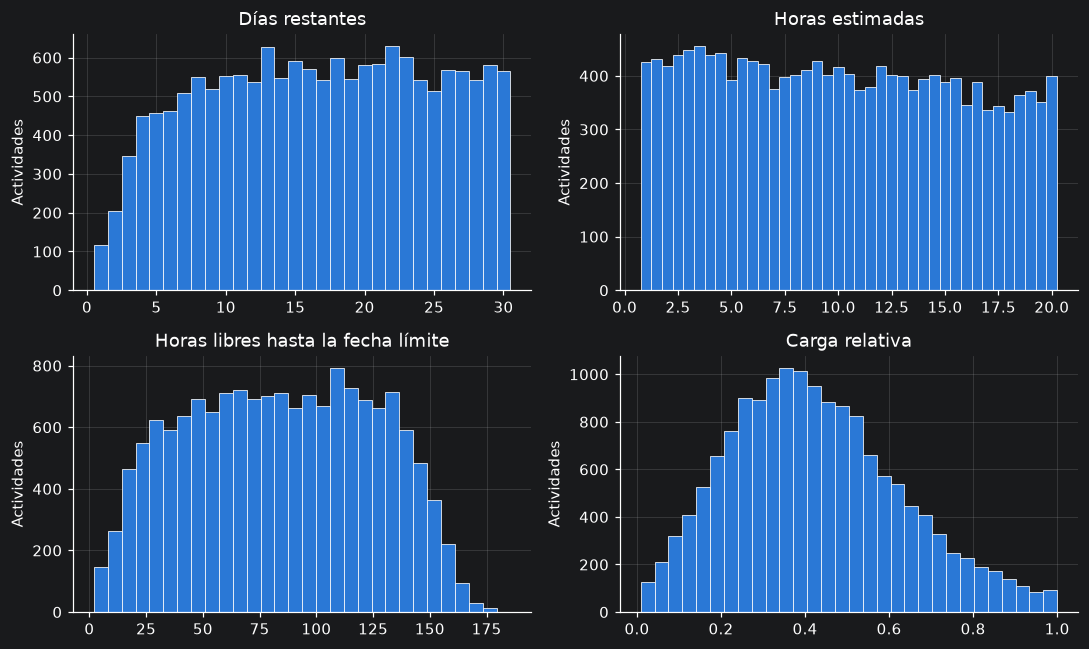

In [17]:
cols = {"dias_restantes": "Días restantes", "horas_estimadas": "Horas estimadas",
        "horas_disponibles_ventana": "Horas libres hasta la fecha límite", "carga_relativa": "Carga relativa"}

bins = {"dias_restantes": np.arange(0.5, 31.5, 1), "horas_estimadas": np.arange(0.75, 20.5, 0.5),
        "horas_disponibles_ventana": 30, "carga_relativa": 30}

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, (c, nombre) in zip(axes.ravel(), cols.items()):
    ax.hist(df[c], bins=bins[c], color=azul, edgecolor="white", linewidth=0.5)
    ax.set_title(nombre)
    ax.set_ylabel("Actividades")
plt.tight_layout()
plt.show()

**Observaciones**

1. **Días restantes:** van de 1 a 30 con mediana 17. Hay menos actividades con plazo corto (27 % en los primeros 10 días contra 37 % en cada uno de los otros dos tercios). Es efecto del validador: un plazo corto con muchas horas casi nunca cabe, y esos escenarios se descartaron.
2. **Horas estimadas:** de 1 a 20 horas, bastante parejas (mediana 10).
3. **Horas libres:** crecen con los días disponibles (mediana 84.5 h, y el 95 % de los casos queda por debajo de 148 h).
4. **Carga relativa:** nunca pasa de 1 porque el validador no deja pasar escenarios imposibles. La mediana es 0.40 y solo el 5 % de las actividades supera 0.80. La red verá pocos casos de carga muy alta.

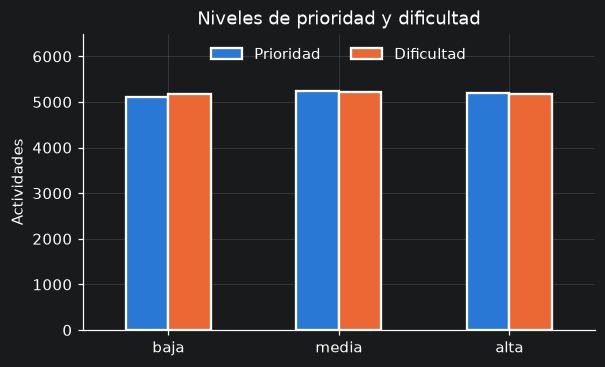

In [18]:
orden = ["baja", "media", "alta"]
niveles = pd.DataFrame({"Prioridad": df["prioridad"].value_counts(),
                        "Dificultad": df["dificultad"].value_counts()}).loc[orden]

ax = niveles.plot.bar(color=[azul, naranja], rot=0, figsize=(6, 3.5), edgecolor="white", linewidth=1.5)
ax.set_ylabel("Actividades")
ax.set_title("Niveles de prioridad y dificultad")
ax.set_ylim(0, 6500)
ax.legend(ncol=2, loc="upper center", frameon=False)
plt.show()

**Observación:** los tres niveles de prioridad y de dificultad están balanceados (alrededor de un tercio cada uno, entre 5114 y 5245 actividades por nivel). Eso es lo esperado porque se sortean al azar, y evita que la red aprenda un nivel mucho mejor que otro.

## 2.4 Mirar las etiquetas y entender al profesor

El **profesor heurístico** es la regla con la que etiquetamos. La red no la conoce: la tiene que aprender viendo ejemplos.

* **Prioridad:** `0.40·urgencia + 0.25·prioridad + 0.20·dificultad + 0.15·carga`, donde `urgencia = 1 - días/30`.
* **Reparto:** primero se calcula qué tanto conviene *adelantar* el trabajo, `s = 0.5·dificultad + 0.3·carga + 0.2·horas`, y se pasa por un softmax con logits `[2.5·s, 0.5, 0]` para obtener inicio, medio y final.

**¿Por qué estas reglas?** Tienen sentido pedagógico: lo que vence pronto, lo que el estudiante marcó como importante, lo difícil y lo muy cargado debe atenderse primero; y lo difícil, grande y con carga alta conviene empezarlo temprano. **La red aprenderá exactamente lo que esta regla le enseñe**, así que la regla debe poder defenderse en el informe.

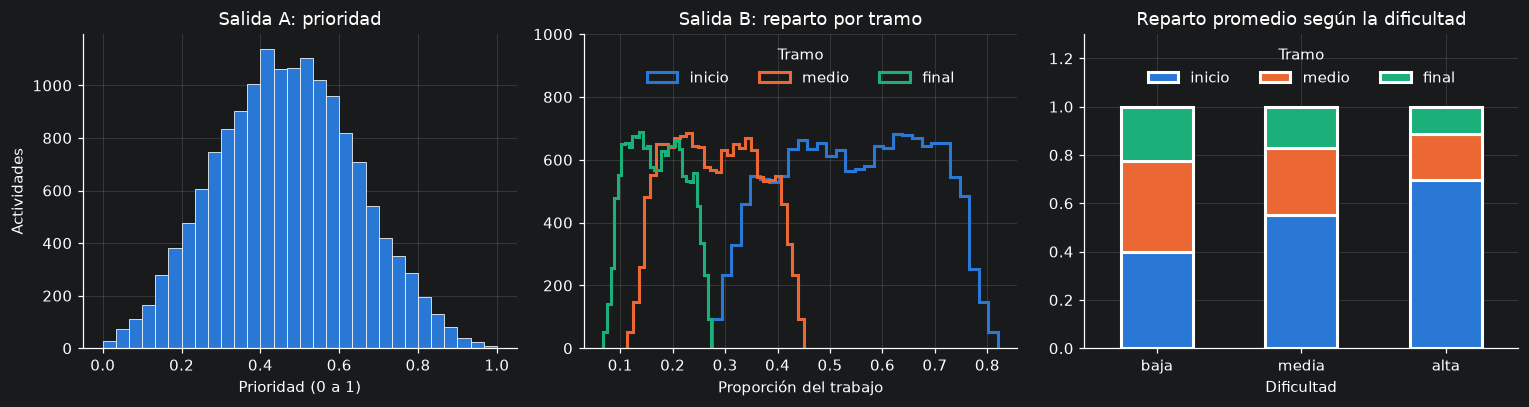

In [19]:
fig, (a, b, c) = plt.subplots(1, 3, figsize=(14, 3.8))

# Salida A: distribución de la prioridad
a.hist(df["y_prioridad"], bins=30, color=azul, edgecolor="white", linewidth=0.5)
a.set_title("Salida A: prioridad")
a.set_xlabel("Prioridad (0 a 1)")
a.set_ylabel("Actividades")

# Salida B: distribución de cada tramo del reparto
for col, color, nombre in [("y_reparto_inicio", azul, "inicio"), ("y_reparto_medio", naranja, "medio"),
                           ("y_reparto_final", celeste, "final")]:
    b.hist(df[col], bins=30, histtype="step", linewidth=2, color=color, label=nombre)
b.set_title("Salida B: reparto por tramo")
b.set_xlabel("Proporción del trabajo")
b.set_ylim(0, 1000)
b.legend(title="Tramo", ncol=3, loc="upper center", frameon=False)

# Cómo cambia el reparto promedio según la dificultad
medias = df.groupby("dificultad")[["y_reparto_inicio", "y_reparto_medio", "y_reparto_final"]].mean().loc[orden]
medias.columns = ["inicio", "medio", "final"]
medias.plot.bar(stacked=True, ax=c, color=[azul, naranja, celeste], rot=0, edgecolor="white", linewidth=2)
c.set_title("Reparto promedio según la dificultad")
c.set_xlabel("Dificultad")
c.set_ylim(0, 1.3)
c.legend(title="Tramo", ncol=3, loc="upper center", frameon=False)

plt.tight_layout()
plt.show()

**Observaciones**

1. **Prioridad:** cubre casi todo el rango de 0 a 1, con promedio 0.47 y desviación 0.18. Hay actividades de todos los niveles de urgencia, así que el orden se puede aprender.
2. **Reparto:** en promedio es `[0.55, 0.28, 0.17]`, y en el **86 % de las actividades el tramo más grande es el inicial**. El profesor adelanta casi siempre el trabajo. Es una decisión de diseño que hay que justificar (o suavizar), porque la red va a recibir muy pocos ejemplos que reparten hacia el final.
3. **Efecto de la dificultad (gráfica de la derecha):** con dificultad baja el inicio recibe 40 % del trabajo, con media 55 % y con alta 70 %. Es justo lo que queremos que el profesor enseñe: lo difícil se empieza antes.

## 2.5 ¿Qué tan difícil es el problema? Líneas base

Antes de entrenar la red conviene saber cuánto se logra **sin** ella. Calculamos las dos líneas base del Paso 1 con el conjunto de entrenamiento y las evaluamos en el de **prueba**:

1. **Predecir el promedio:** ignora las entradas y siempre responde el promedio de entrenamiento.
2. **Regresión lineal:** una combinación ponderada de las 6 entradas (mínimos cuadrados). Es lo más simple que usa la información.

In [20]:
ENTRADAS = ["x_dias", "x_prioridad", "x_dificultad", "x_horas", "x_ventana", "x_carga"]
TRAMOS = ["y_reparto_inicio", "y_reparto_medio", "y_reparto_final"]
train, val, test = (df[df["conjunto"] == c] for c in ["train", "val", "test"])

def con_sesgo(d):
    """agrega una columna de 1s para el término independiente"""
    return np.c_[np.ones(len(d)), d[ENTRADAS].values]

# Regresión lineal ajustada solo con entrenamiento
w_prio = np.linalg.lstsq(con_sesgo(train), train["y_prioridad"].values, rcond=None)[0]
w_rep = np.linalg.lstsq(con_sesgo(train), train[TRAMOS].values, rcond=None)[0]
pred_prio = con_sesgo(test) @ w_prio
pred_rep = con_sesgo(test) @ w_rep

# Métricas en prueba
spearman = spearmanr(pred_prio, test["y_prioridad"])[0]
mae_media = np.abs(train[TRAMOS].mean().values - test[TRAMOS].values).mean(axis=0)
mae_lineal = np.abs(pred_rep - test[TRAMOS].values).mean(axis=0)

# predecir el promedio da una salida constante y su Spearman no está definido, en ese casi se muestra 0.
resultados = pd.DataFrame(
    {"Spearman prioridad": [0.0, spearman, 0.90],
     "MAE inicio": [*mae_media[:1], *mae_lineal[:1], 0.05],
     "MAE medio": [*mae_media[1:2], *mae_lineal[1:2], 0.05],
     "MAE final": [*mae_media[2:], *mae_lineal[2:], 0.05]},
    index=["Predecir el promedio", "Regresión lineal", "Objetivo del proyecto"]).round(4)
resultados

,Spearman prioridad,MAE inicio,MAE medio,MAE final
Predecir el promedio,0.0000,0.1154,0.0719,0.0436
Regresión lineal,0.9929,0.0035,0.0022,0.0013
Objetivo del proyecto,0.9000,0.0500,0.0500,0.0500


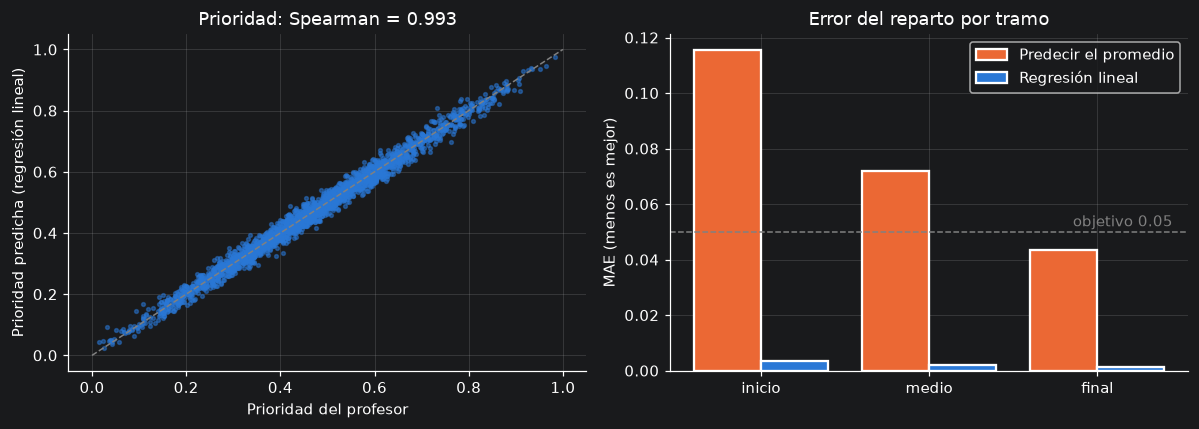

In [21]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))

# Regresión lineal: predicho vs real (conjunto de prueba)
a.scatter(test["y_prioridad"], pred_prio, s=6, color=azul, alpha=0.5)
a.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1)
a.set_xlabel("Prioridad del profesor")
a.set_ylabel("Prioridad predicha (regresión lineal)")
a.set_title(f"Prioridad: Spearman = {spearman:.3f}")

# MAE por tramo de cada línea base frente al objetivo
x = np.arange(3)
b.bar(x - 0.2, mae_media, width=0.4, color=naranja, edgecolor="white", linewidth=1.5, label="Predecir el promedio")
b.bar(x + 0.2, mae_lineal, width=0.4, color=azul, edgecolor="white", linewidth=1.5, label="Regresión lineal")
b.axhline(0.05, color="gray", linestyle="--", linewidth=1)
b.text(2.45, 0.052, "objetivo 0.05", ha="right", color="gray")
b.set_xticks(x)
b.set_xticklabels(["inicio", "medio", "final"])
b.set_ylabel("MAE (menos es mejor)")
b.set_title("Error del reparto por tramo")
b.legend()

plt.tight_layout()
plt.show()

**Observaciones:**

1. **La regresión lineal ya cumple los dos objetivos del proyecto:** Spearman 0.993 (se pedía ≥ 0.90) y MAE de 0.0035, 0.0022 y 0.0013 (se pedía ≤ 0.05).
2. **El objetivo del reparto es muy fácil:** incluso predecir siempre el promedio da MAE 0.115, 0.072 y 0.044. El tramo final ya cumple el objetivo sin aprender nada, porque casi no varía.
3. **¿Por qué pasa esto?** Porque el profesor es casi lineal: la prioridad es una suma ponderada exacta de las entradas, y el reparto, aunque usa un softmax, queda casi lineal en el rango de los datos. Una red con capas ocultas no puede ganarle a un modelo que ya acierta casi todo.
4. **Consecuencia:** si la red saca 0.99 de Spearman, no demuestra que sea mejor que una regresión lineal. Hay que decidir cómo justificar la red (ver 2.6) antes de entrenarla.

## 2.6 Decisiones finales

En 2.5 vimos que con la v1 el problema era demasiado fácil: una regresión lineal ya cumplía los objetivos del proyecto. Para que la red tenga algo real que aprender, el equipo fijó las siguientes decisiones, que son las definitivas para el dataset.

**El profesor deja de ser lineal.** La idea parte del caso de un estudiante que tiene que cuadrar muchas actividades en pocos días: ahí la prioridad no sube de forma pareja, sube de golpe. La red no recibe "cuántas actividades hay" como entrada, pero la carga relativa ya resume cuántas horas hay que cuadrar hasta cada fecha, así que la no linealidad se construye con los días y la carga:

* La urgencia cae rápido en la última semana: pasa de `1 − días/30` (una recta) a `1 / (1 + días/5)`.
* Se agrega el **aprieto**, `urgencia × carga_alta`, donde `carga_alta` pasa de 0 a 1 de forma suave alrededor de una carga de 0.5. Solo es alto cuando se juntan pocos días y mucha carga.
* La prioridad queda como `0.20·urgencia + 0.15·prioridad + 0.15·dificultad + 0.10·carga + 0.40·aprieto`.
* El aprieto también cuenta en el reparto, porque si hay apuro conviene empezar ya.

**El margen del validador se queda en 0.0.** Si las horas de un escenario caben justo en el tiempo disponible, se acepta; si lo superan, se descarta. Un caso exacto agrega dificultad sin volverse imposible.

**El plazo mínimo es de 3 días.** Con menos tiempo no se pueden formar los 3 tramos del reparto y repartir el estudio no tiene sentido. Por eso el dataset solo tiene actividades con 3 a 30 días.

**El reparto se suaviza.** En lugar del softmax de la v1, se mezcla un perfil relajado con uno adelantado. El motivo y los detalles se explican en 2.7.

**¿Por qué una versión 2 del dataset?** Estas decisiones cambian cómo se generan los datos (la regla del profesor, los plazos y el reparto), así que no bastaba con corregir el dataset anterior: había que generar uno nuevo con las reglas nuevas. Se conservan los dos a propósito:

* La **v1** (`generar_dataset.py` y `data/dataset_studyflow.csv`) es con la que están hechas las secciones 2.1 a 2.5. Muestra el problema que motivó los cambios, y si se reemplazara, esas secciones ya no darían los mismos resultados al ejecutar el notebook.
* La **v2** (`generar_dataset_v2.py` y `data/dataset_studyflow_v2.csv`) incluye las decisiones de esta sección. Se usa desde 2.8, se compara con la v1 en 2.9 y es la única con la que se entrena la red.

## 2.7 El reparto "muy adelantado": por qué se cambió

El **reparto** dice cuántas de las horas de una actividad se hacen en el primer, segundo y último tercio del tiempo que queda. El profesor lo calcula en dos pasos: primero un número `s` entre 0 y 1 que dice **cuánto conviene adelantar** (más alto si la actividad es difícil, está muy cargada o es larga), y luego convierte `s` en tres proporciones que suman 1.

En la v1 esa conversión (un softmax) tenía dos efectos que no eran decisiones pedagógicas, sino consecuencias de la fórmula:

1. **Nunca dejaba más trabajo para el final que para el inicio.** Por eso el 86 % de las actividades tenía el mayor peso al inicio, y la red nunca vería un caso de "esto puede esperar".
2. **Extremos raros:** la actividad más fácil y corta salía `[0.27, 0.45, 0.27]`, con un pico en el medio que nadie pidió, y la más difícil `[0.82, 0.11, 0.07]`, es decir, 82 % de las horas en el primer tercio. Con 6 días serían 2 días con casi todo el trabajo, lo que choca con el máximo de horas por día de la capa de asignación. El documento del proyecto usa como ejemplo `[0.5, 0.3, 0.2]`, mucho más moderado.

**¿Por qué importa?** Porque la red solo aprende lo que ve. Con poca variedad en el reparto, cualquier modelo acierta (incluso predecir el promedio) y el experimento no demuestra nada.

**Decisión final (v2):** mezclar dos perfiles según `s`: uno **relajado** `[0.25, 0.35, 0.40]` (lo fácil puede esperar) y uno **adelantado** `[0.60, 0.28, 0.12]` (lo difícil o apretado se empieza ya). Es más moderado, deja ver los dos extremos y conserva la idea del documento: cuanto más difícil, más se adelanta.

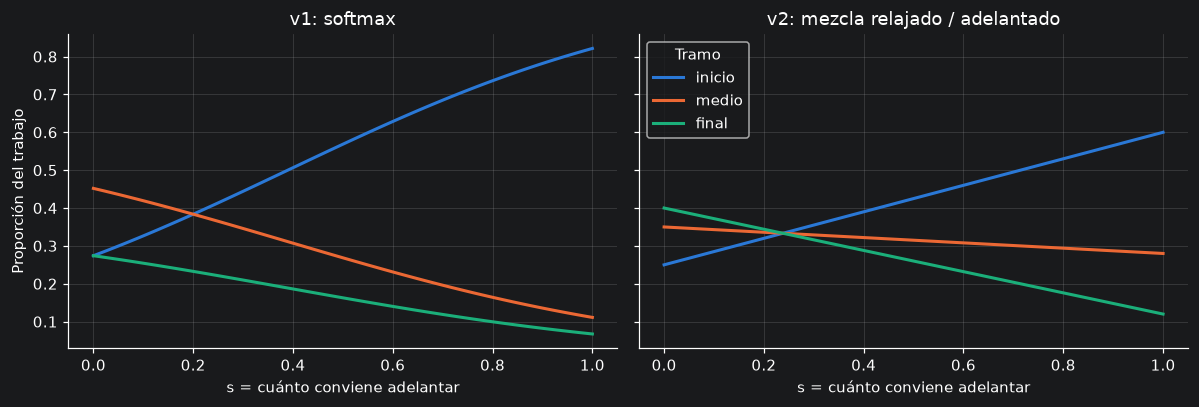

In [22]:
s = np.linspace(0, 1, 101)

# v1: softmax con logits [2.5·s, 0.5, 0]
logits = np.stack([2.5 * s, np.full_like(s, 0.5), np.zeros_like(s)], axis=1)
v1 = np.exp(logits) / np.exp(logits).sum(axis=1, keepdims=True)

# v2: mezcla entre un reparto relajado y uno adelantado
relajado, adelantado = np.array([0.25, 0.35, 0.40]), np.array([0.60, 0.28, 0.12])
v2 = (1 - s)[:, None] * relajado + s[:, None] * adelantado

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, perfil, titulo in [(a, v1, "v1: softmax"), (b, v2, "v2: mezcla relajado / adelantado")]:
    for k, (nombre, color) in enumerate([("inicio", azul), ("medio", naranja), ("final", celeste)]):
        ax.plot(s, perfil[:, k], color=color, linewidth=2, label=nombre)
    ax.set_title(titulo)
    ax.set_xlabel("s = cuánto conviene adelantar")
a.set_ylabel("Proporción del trabajo")
b.legend(title="Tramo")
plt.tight_layout()
plt.show()

**Observaciones**

1. **v1 (izquierda):** el tramo inicial sube de 0.27 a 0.82 y el final nunca pasa de 0.27. Nunca hay un caso en que el final pese más que el inicio, y con `s = 0` el medio forma una "joroba".
2. **v2 (derecha):** las tres curvas se cruzan en `s ≈ 0.24`, donde el reparto es parejo `[⅓, ⅓, ⅓]`. Por debajo de ese punto (lo fácil, corto y sin presión) el final pesa más; por encima (lo difícil o apretado) el inicio pesa más y llega a 0.60.
3. **El tramo medio casi no cambia** (entre 0.28 y 0.35): es el punto intermedio entre empezar pronto y dejarlo para el final. Es normal, pero significa que esa salida tendrá poco que aprender.

## 2.8 El dataset v2

Se genera igual que en 2.1 con `generar_dataset_v2.py`, pero con los cambios de las decisiones:

| Aspecto | v1 | v2 |
|---|---|---|
| Plazo | 1 a 30 días | **3 a 30 días** |
| Validador | `MARGEN = 0.0` | `MARGEN = 0.0` (igual) |
| Urgencia | `1 − días/30` | `1 / (1 + días/5)` |
| Prioridad | suma ponderada (lineal) | suma ponderada **+ aprieto** (no lineal) |
| Reparto | softmax | mezcla relajado / adelantado |
| Lo demás | 3000 escenarios, 3 a 8 actividades, 2 a 8 horas libres por día, división 70/15/15 por escenario | igual |

In [23]:
df2 = pd.read_csv("../data/dataset_studyflow_v2.csv")
print("Actividades (filas):", len(df2), "| Escenarios:", df2["escenario_id"].nunique())
print(df2["conjunto"].value_counts().to_string())
print("Plazo mínimo y máximo:", df2["dias_restantes"].min(), "y", df2["dias_restantes"].max())
print("Carga relativa máxima:", df2["carga_relativa"].max())

Actividades (filas): 15995 | Escenarios: 3000
conjunto
train    11199
val       2408
test      2388
Plazo mínimo y máximo: 3 y 30
Carga relativa máxima: 1.0


**Observaciones**

1. El plazo mínimo ahora es 3 días y la carga relativa llega exactamente a 1.0: los escenarios que caben justo se aceptan.
2. Se aceptó el 85.5 % de los escenarios generados (3510 intentos para 3000 escenarios; en la v1 fue 67.5 %). Al quitar los plazos de 1 y 2 días desaparecen muchos casos imposibles.
3. Quedaron 15 995 actividades: 11 199 en entrenamiento, 2408 en validación y 2388 en prueba.

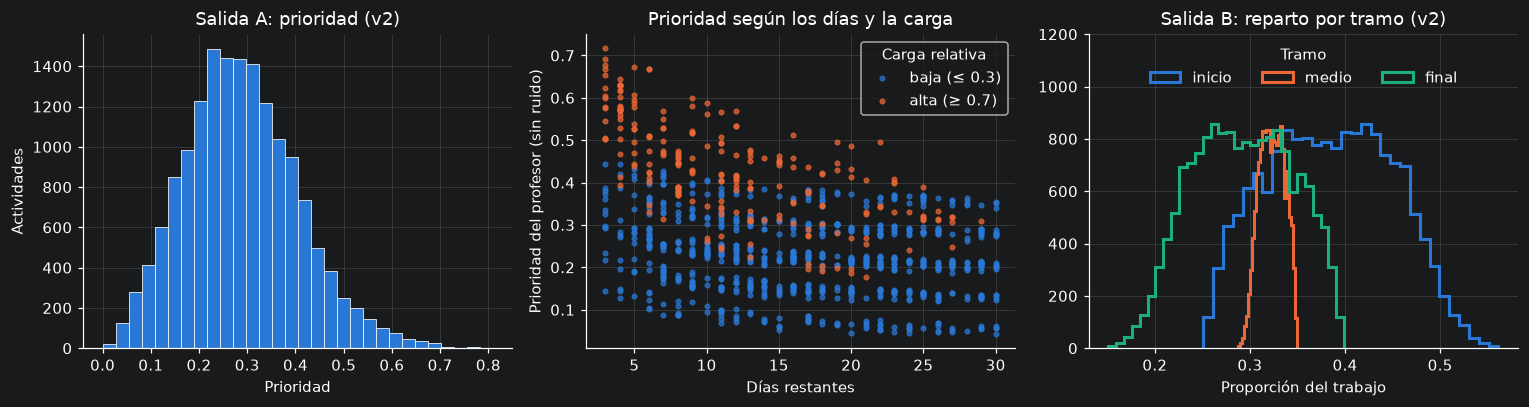

In [24]:
fig, (a, b, c) = plt.subplots(1, 3, figsize=(14, 3.8))

# Salida A: distribución de la prioridad v2
a.hist(df2["y_prioridad"], bins=30, color=azul, edgecolor="white", linewidth=0.5)
a.set_title("Salida A: prioridad (v2)")
a.set_xlabel("Prioridad")
a.set_ylabel("Actividades")

# La no linealidad: prioridad según los días, con carga baja y con carga alta
muestra = df2.sample(2500, random_state=0)
for filtro, color, nombre in [(muestra["carga_relativa"] <= 0.3, azul, "baja (≤ 0.3)"),
                              (muestra["carga_relativa"] >= 0.7, naranja, "alta (≥ 0.7)")]:
    m = muestra[filtro]
    b.scatter(m["dias_restantes"], m["y_prioridad_sin_ruido"], s=9, color=color, alpha=0.7, label=nombre)
b.set_title("Prioridad según los días y la carga")
b.set_xlabel("Días restantes")
b.set_ylabel("Prioridad del profesor (sin ruido)")
b.legend(title="Carga relativa")

# Salida B: distribución de cada tramo del reparto v2
for col, color, nombre in [("y_reparto_inicio", azul, "inicio"), ("y_reparto_medio", naranja, "medio"),
                           ("y_reparto_final", celeste, "final")]:
    c.hist(df2[col], bins=30, histtype="step", linewidth=2, color=color, label=nombre)
c.set_title("Salida B: reparto por tramo (v2)")
c.set_xlabel("Proporción del trabajo")
c.set_ylim(0, 1200)
c.legend(title="Tramo", ncol=3, loc="upper center", frameon=False)

plt.tight_layout()
plt.show()

**Observaciones**

1. **Prioridad (izquierda):** el promedio bajó a 0.29 (antes 0.47) y llega hasta 0.81. Es esperable: la urgencia ahora solo es alta en los últimos días. Como lo que importa es el **orden**, el objetivo no cambia, pero hay que recordarlo al leer valores como "0.62".
2. **La no linealidad (centro):** la prioridad ya no baja en línea recta con los días. Cae rápido al principio y luego se aplana: promedio 0.42 con 3 a 5 días, 0.34 con 6 a 10, 0.28 con 11 a 20 y 0.25 con 21 a 30. Además, con pocos días la carga marca la diferencia: con 5 días o menos, la prioridad promedio es 0.56 si la carga es alta (≥ 0.7) y 0.29 si es baja (≤ 0.3).
3. **Reparto (derecha):** el promedio es `[0.39, 0.32, 0.29]`. El inicio va de 0.25 a 0.56 y el final de 0.15 a 0.40. Ahora el 75 % de las actividades pone el mayor peso al inicio y el 25 % al final (antes: 86 % al inicio, 14 % al medio y ninguna al final).

## 2.9 Líneas base con el dataset v2

Repetimos las líneas base de 2.5, ahora con la v2. Además del Spearman agregamos el **R²** de la prioridad contra la que pondría el profesor sin ruido (1.0 significa que el modelo reproduce la regla exactamente). Lo agregamos porque el Spearman solo mira el orden y casi no distingue entre modelos buenos.

In [25]:
train2, val2, test2 = (df2[df2["conjunto"] == c] for c in ["train", "val", "test"])

w_prio2 = np.linalg.lstsq(con_sesgo(train2), train2["y_prioridad"].values, rcond=None)[0]
w_rep2 = np.linalg.lstsq(con_sesgo(train2), train2[TRAMOS].values, rcond=None)[0]
pred_prio2 = con_sesgo(test2) @ w_prio2
pred_rep2 = con_sesgo(test2) @ w_rep2

def r2(real, pred):
    return 1 - ((real - pred) ** 2).sum() / ((real - real.mean()) ** 2).sum()

y_limpia = test2["y_prioridad_sin_ruido"].values
spearman2 = spearmanr(pred_prio2, test2["y_prioridad"])[0]
mae_media2 = np.abs(train2[TRAMOS].mean().values - test2[TRAMOS].values).mean(axis=0)
mae_lineal2 = np.abs(pred_rep2 - test2[TRAMOS].values).mean(axis=0)

resultados2 = pd.DataFrame(
    [[spearman, r2(test["y_prioridad_sin_ruido"].values, pred_prio), *mae_lineal],
     [0.0, r2(y_limpia, train2["y_prioridad"].mean()), *mae_media2],
     [spearman2, r2(y_limpia, pred_prio2), *mae_lineal2],
     [0.90, np.nan, 0.05, 0.05, 0.05]],
    columns=["Spearman prioridad", "R² prioridad", "MAE inicio", "MAE medio", "MAE final"],
    index=["v1 · regresión lineal", "v2 · predecir el promedio", "v2 · regresión lineal", "Objetivo del proyecto"]).round(4)
resultados2

,Spearman prioridad,R² prioridad,MAE inicio,MAE medio,MAE final
v1 · regresión lineal,0.9929,1.0000,0.0035,0.0022,0.0013
v2 · predecir el promedio,0.0000,-0.0003,0.0543,0.0109,0.0435
v2 · regresión lineal,0.9680,0.9540,0.0029,0.0006,0.0023
Objetivo del proyecto,0.9000,NaN,0.0500,0.0500,0.0500


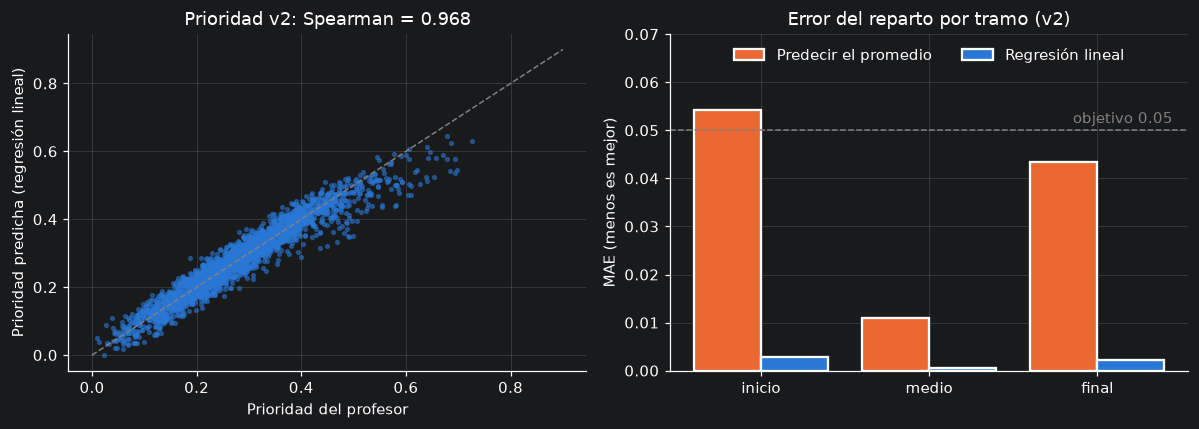

In [26]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))

# Regresión lineal con la v2: predicho vs real (conjunto de prueba)
a.scatter(test2["y_prioridad"], pred_prio2, s=6, color=azul, alpha=0.5)
a.plot([0, 0.9], [0, 0.9], color="gray", linestyle="--", linewidth=1)
a.set_xlabel("Prioridad del profesor")
a.set_ylabel("Prioridad predicha (regresión lineal)")
a.set_title(f"Prioridad v2: Spearman = {spearman2:.3f}")

# MAE por tramo de cada línea base frente al objetivo
x = np.arange(3)
b.bar(x - 0.2, mae_media2, width=0.4, color=naranja, edgecolor="white", linewidth=1.5, label="Predecir el promedio")
b.bar(x + 0.2, mae_lineal2, width=0.4, color=azul, edgecolor="white", linewidth=1.5, label="Regresión lineal")
b.axhline(0.05, color="gray", linestyle="--", linewidth=1)
b.text(2.45, 0.0515, "objetivo 0.05", ha="right", color="gray")
b.set_xticks(x)
b.set_xticklabels(["inicio", "medio", "final"])
b.set_ylabel("MAE (menos es mejor)")
b.set_title("Error del reparto por tramo (v2)")
b.set_ylim(0, 0.07)
b.legend(ncol=2, loc="upper center", frameon=False)

plt.tight_layout()
plt.show()

**Observaciones: qué cambió con la no linealidad**

1. **La regresión lineal ya no reproduce al profesor:** su R² contra la prioridad sin ruido bajó de 1.00 a 0.95 y su Spearman de 0.993 a 0.968. En la gráfica de la izquierda los puntos ya no caen sobre la diagonal: aparece una nube de error que antes no existía, y la regresión se queda corta justo en los casos más apretados (en el 4.4 % de actividades con prioridad ≥ 0.5 predice en promedio 0.054 menos de lo real).
2. **Aun así, los objetivos del documento siguen siendo fáciles:** la regresión lineal pasa el Spearman ≥ 0.90 y el MAE del reparto es de apenas 0.003, 0.001 y 0.002. Predecir el promedio ya cumple el MAE en dos de los tres tramos (medio y final); solo falla en el inicial (0.054).
3. **El reparto sigue siendo casi lineal.** La no linealidad que agregamos vive sobre todo en la prioridad.
4. **Qué significa para el Paso 3:** como el Spearman casi no separa a los modelos, además de los objetivos del documento mediremos si la red **baja el error de prioridad frente a la regresión lineal** (R² de 0.95 como punto de partida). Si la red no lo mejora, no se justifica usarla.

## 2.10 Preparar los datos para la red

A partir de aquí se usa **solo la v2**. Los datos ya están escalados a [-1, 1] y divididos por escenario (columna `conjunto`), así que solo separamos entradas y salidas. Primero comprobamos que los tres conjuntos se parecen entre sí.

In [27]:
print(df2.groupby("conjunto")[["y_prioridad"] + TRAMOS].agg(["mean", "std"]).round(3).to_string())

# Entradas (X) y salidas (A = prioridad, B = reparto) de cada conjunto
X_train, X_val, X_test = (d[ENTRADAS].values for d in (train2, val2, test2))
A_train, A_val, A_test = (d["y_prioridad"].values for d in (train2, val2, test2))
B_train, B_val, B_test = (d[TRAMOS].values for d in (train2, val2, test2))

print("\nX_train:", X_train.shape, "| A_train:", A_train.shape, "| B_train:", B_train.shape)
print("X_val:  ", X_val.shape, "| X_test:", X_test.shape)
print("Suma del reparto (min, max):", B_train.sum(axis=1).min(), B_train.sum(axis=1).max())

         y_prioridad        y_reparto_inicio        y_reparto_medio        y_reparto_final       
                mean    std             mean    std            mean    std            mean    std
conjunto                                                                                         
test           0.285  0.117            0.383  0.064           0.323  0.013           0.294  0.051
train          0.287  0.117            0.385  0.065           0.323  0.013           0.292  0.052
val            0.294  0.123            0.387  0.065           0.323  0.013           0.291  0.052

X_train: (11199, 6) | A_train: (11199,) | B_train: (11199, 3)
X_val:   (2408, 6) | X_test: (2388, 6)
Suma del reparto (min, max): 0.9999999999999999 1.0000000000000002


**Observaciones**

1. Los tres conjuntos son parecidos (prioridad promedio 0.287, 0.294 y 0.285 en entrenamiento, validación y prueba), así que la división es representativa.
2. Entrenamiento tiene 11 199 actividades, validación 2408 y prueba 2388. La validación sirve para vigilar el entrenamiento y la prueba solo se usa al final.
3. El reparto suma 1 en todas las filas, como exige la salida softmax.

---

# PASO 3. DESARROLLAR LA RED

## 3.1 Qué red vamos a construir

La red recibe las 6 características de una actividad y devuelve dos cosas a la vez: su **prioridad** (un número entre 0 y 1) y su **reparto** (qué fracción del trabajo va al inicio, al medio y al final, que suma 1). Por eso es una red *multitarea*: una parte compartida aprende una representación de la actividad y dos cabezas distintas la convierten en cada salida.

```
Entrada (6) -> Dense 32 (ReLU) -> Dense 16 (ReLU) -> Dense 1 (sigmoide)  -> prioridad
                                                  -> Dense 3 (softmax)   -> reparto
```

* **Capas compartidas, 32 y 16 neuronas con ReLU:** son pocas porque el problema es pequeño (6 entradas) y la relación que debe aprender (el aprieto) es suave. ReLU es la activación estándar de las capas ocultas.
* **Sigmoide en la prioridad:** deja la salida entre 0 y 1, igual que la prioridad del profesor.
* **Softmax en el reparto:** hace que las tres salidas sean positivas y sumen 1, como un reparto real.

En el laboratorio usamos la API **secuencial** de Keras (`Sequential`), que apila capas una tras otra y solo permite una entrada y una salida. Aquí hay dos salidas que parten de la misma capa oculta, así que usamos la **API funcional**: cada capa se llama sobre la anterior (`capa(entrada)`) y al final se declara qué es entrada y qué es salida con `keras.Model`.

In [28]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import keras
from keras import layers

def crear_modelo():
    entrada = keras.Input(shape=(6,), name="entradas")
    h = layers.Dense(32, activation="relu")(entrada)
    h = layers.Dense(16, activation="relu")(h)
    prioridad = layers.Dense(1, activation="sigmoid", name="prioridad")(h)
    reparto = layers.Dense(3, activation="softmax", name="reparto")(h)
    return keras.Model(entrada, [prioridad, reparto])

crear_modelo().summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ entradas            │ (None, 6)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │        224 │ entradas[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 16)        │        528 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ prioridad (Dense)   │ (None, 1)         │         17 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reparto (Dense)     │ (None, 3)         │         51 │ dense_3[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 820 (3.20 KB)

 Trainable params: 820 (3.20 KB)

 Non-trainable params: 0 (0.00 B)

## 3.2 Cómo se entrena: pérdida, optimizador y parada

* **Pérdida de la prioridad: error cuadrático medio (MSE)**, porque es un número continuo.
* **Pérdida del reparto: entropía cruzada**, porque la salida es una distribución de probabilidad (softmax) y compara qué tan lejos queda de la distribución del profesor.
* **Pérdida total** = `peso_prioridad · MSE + peso_reparto · entropía`. Los pesos dicen cuál de las dos tareas pesa más al ajustar la parte compartida. Los probamos en 3.3.
* **Optimizador Adam** con tasa de aprendizaje 0.01 y lotes de 64 actividades.
* **Parada temprana:** el entrenamiento se detiene cuando el error en validación lleva 15 épocas sin mejorar y se conservan los pesos de la mejor época. Así no se sobreentrena y no hay que adivinar el número de épocas.

La validación se usa para vigilar y para elegir; el conjunto de prueba no se toca hasta el Paso 4.

## 3.3 Elegir los pesos de la pérdida

Entrenamos la misma red con tres combinaciones de pesos y comparamos en **validación** (nunca en prueba). Los pesos por defecto son 1 y 1; los otros dos priorizan una tarea sobre la otra.

In [29]:
y_limpia_val = val2["y_prioridad_sin_ruido"].values

def entrenar(peso_prio, peso_rep, semilla=0):
    keras.utils.set_random_seed(semilla)
    m = crear_modelo()
    m.compile(optimizer=keras.optimizers.Adam(1e-2),
              loss={"prioridad": "mse", "reparto": "categorical_crossentropy"},
              loss_weights={"prioridad": peso_prio, "reparto": peso_rep})
    parar = keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True)
    hist = m.fit(X_train, {"prioridad": A_train, "reparto": B_train},
                 validation_data=(X_val, {"prioridad": A_val, "reparto": B_val}),
                 epochs=150, batch_size=64, callbacks=[parar], verbose=0)
    return m, hist

def evaluar(m, X, A, B, A_limpia):
    """Spearman y R² de la prioridad, y MAE de cada tramo del reparto."""
    pred_a, pred_b = m.predict(X, verbose=0)
    pred_a = pred_a.ravel()
    return [spearmanr(pred_a, A)[0], r2(A_limpia, pred_a), *np.abs(pred_b - B).mean(axis=0)]

# 3.3 Probar tres combinaciones de pesos (se compara en validación)
columnas = ["Épocas", "Spearman prioridad", "R² prioridad", "MAE inicio", "MAE medio", "MAE final"]
filas, nombres = [], []
for pp, pr in [(1, 1), (10, 1), (1, 10)]:
    m, h = entrenar(pp, pr)
    filas.append([len(h.history["loss"]), *evaluar(m, X_val, A_val, B_val, y_limpia_val)])
    nombres.append(f"prioridad {pp} · reparto {pr}")
pd.DataFrame(filas, columns=columnas, index=nombres).round(4)

,Épocas,Spearman prioridad,R² prioridad,MAE inicio,MAE medio,MAE final
prioridad 1 · reparto 1,68,0.9838,0.9974,0.0013,0.0007,0.0011
prioridad 10 · reparto 1,36,0.9836,0.9972,0.0039,0.0018,0.0027
prioridad 1 · reparto 10,46,0.9836,0.9977,0.0009,0.0004,0.0008


**Observaciones**

1. Las tres combinaciones funcionan bien: R² de la prioridad entre 0.997 y 0.998, Spearman de 0.983 en todas y MAE del reparto de 0.003 o menos, muy por debajo del objetivo de 0.05.
2. Las diferencias entre combinaciones son más pequeñas que la variación entre semillas que vemos en 3.5 (R² de 0.994 a 0.998), así que **no hay una ganadora clara**. Nos quedamos con **1 y 1**, la más simple, y lo comprobamos con varias semillas.

## 3.4 Entrenar la red final y ver cómo aprende

Entrenamos con los pesos elegidos y graficamos el error por época en entrenamiento y validación, para cada salida. Si las dos curvas bajan juntas la red está aprendiendo; si la de validación se separa hacia arriba, estaría memorizando.

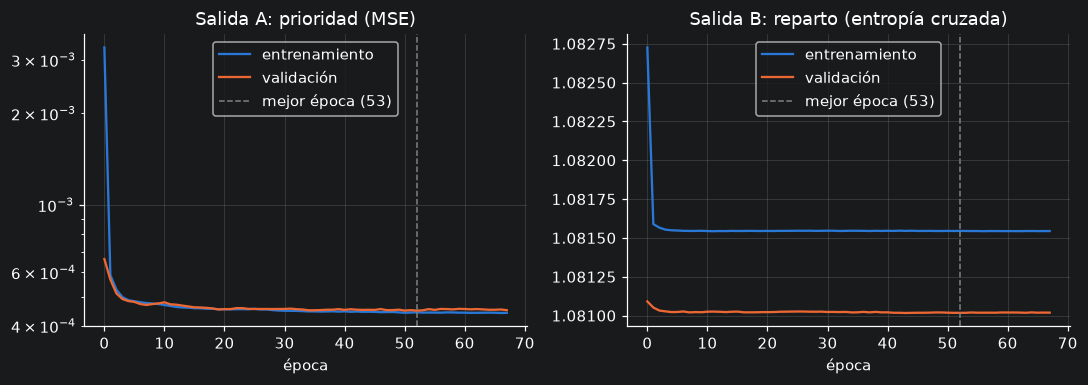

Épocas entrenadas: 68 | mejor época: 53


In [30]:
modelo, hist = entrenar(1, 1)
h = hist.history
mejor = int(np.argmin(h["val_loss"]))

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, clave, titulo in [(a, "prioridad_loss", "Salida A: prioridad (MSE)"),
                          (b, "reparto_loss", "Salida B: reparto (entropía cruzada)")]:
    ax.plot(h[clave], color=azul, label="entrenamiento")
    ax.plot(h["val_" + clave], color=naranja, label="validación")
    ax.axvline(mejor, color="gray", ls="--", lw=1, label=f"mejor época ({mejor + 1})")
    ax.set_xlabel("época"); ax.set_title(titulo); ax.legend()
a.set_yscale("log")
plt.tight_layout(); plt.show()
print("Épocas entrenadas:", len(h["loss"]), "| mejor época:", mejor + 1)

**Observaciones**

1. **La red aprende rápido y no memoriza:** la prioridad pasa de un error de 0.003 a unos 0.0005 en pocas épocas y las curvas de entrenamiento y validación quedan prácticamente juntas. La parada temprana se activó a las 35 épocas y se conservaron los pesos de la época 20.
2. **La curva del reparto está casi plana, y está bien:** la entropía cruzada no puede llegar a 0 porque el reparto del profesor es una distribución suave, no un solo tramo; su piso es la entropía de esa distribución (cerca de 1.08). La red llega a ese piso en dos épocas porque, como vimos en 2.9, el reparto es casi lineal y es fácil de aprender.
3. Que la validación quede por debajo del entrenamiento en algunas épocas no es un error: son escenarios distintos y la curva de entrenamiento es el promedio mientras la red aún cambia.

## 3.5 ¿Depende de la semilla?

Los pesos iniciales de la red son aleatorios, así que un resultado bueno podría ser suerte. Repetimos el entrenamiento con 5 semillas distintas y miramos la variación en validación.

In [31]:
filas = []
for semilla in range(5):
    m, h5 = entrenar(1, 1, semilla)
    filas.append([len(h5.history["loss"]), *evaluar(m, X_val, A_val, B_val, y_limpia_val)])
semillas = pd.DataFrame(filas, columns=columnas, index=[f"semilla {s}" for s in range(5)])
pd.concat([semillas, semillas.agg(["min", "max"])]).round(4)

,Épocas,Spearman prioridad,R² prioridad,MAE inicio,MAE medio,MAE final
semilla 0,68,0.9838,0.9974,0.0013,0.0007,0.0011
semilla 1,28,0.9837,0.9974,0.0015,0.0008,0.0011
semilla 2,71,0.9834,0.9968,0.0009,0.0006,0.0007
semilla 3,32,0.9834,0.9971,0.0016,0.0007,0.0014
semilla 4,40,0.9835,0.9980,0.0019,0.0008,0.0016
min,28,0.9834,0.9968,0.0009,0.0006,0.0007
max,71,0.9838,0.9980,0.0019,0.0008,0.0016


**Observaciones**

1. Los resultados casi no cambian con la semilla: Spearman entre 0.9830 y 0.9837, MAE del reparto de 0.0018 o menos y R² de la prioridad entre 0.994 y 0.998.
2. La semilla 2 es la peor en R² (0.994), pero sigue muy por encima de la regresión lineal (0.954 en prueba). La ventaja de la red no es suerte de una inicialización.

---

# PASO 4. EVALUAR Y REDACTAR CONCLUSIONES

## 4.1 Resultado en el conjunto de prueba

Ahora sí usamos el conjunto de prueba, una sola vez, con la red entrenada en 3.4. Se compara con las líneas base de 2.9 (que también se calcularon sobre prueba) y con los objetivos del proyecto.

In [32]:
y_limpia = test2["y_prioridad_sin_ruido"].values
metricas_red = evaluar(modelo, X_test, A_test, B_test, y_limpia)

resultados3 = pd.concat([
    resultados2.iloc[[1, 2]],
    pd.DataFrame([metricas_red], columns=resultados2.columns, index=["v2 · red neuronal"]),
    resultados2.iloc[[3]]]).round(4)
resultados3.index = [n.replace("v2 · ", "") for n in resultados3.index]
resultados3

,Spearman prioridad,R² prioridad,MAE inicio,MAE medio,MAE final
predecir el promedio,0.0000,-0.0003,0.0543,0.0109,0.0435
regresión lineal,0.9680,0.9540,0.0029,0.0006,0.0023
red neuronal,0.9813,0.9972,0.0013,0.0007,0.0011
Objetivo del proyecto,0.9000,NaN,0.0500,0.0500,0.0500


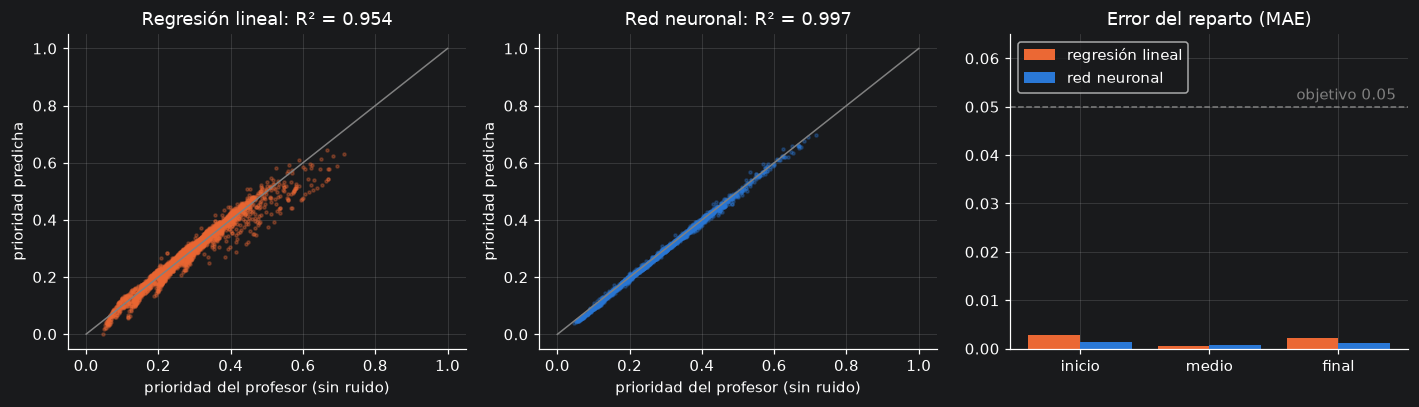

Actividades con prioridad >= 0.5: 96 (4.0%)
Error promedio de la prioridad en ellas -> lineal: 0.0600 | red: 0.0078
Error promedio en todas                 -> lineal: 0.0173 | red: 0.0046


In [33]:
pred_red = modelo.predict(X_test, verbose=0)[0].ravel()
pred_rep_red = modelo.predict(X_test, verbose=0)[1]
mae_red = np.abs(pred_rep_red - B_test).mean(axis=0)

fig, (a, b, c) = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, pred, color, nombre in [(a, pred_prio2, naranja, "Regresión lineal"), (b, pred_red, azul, "Red neuronal")]:
    ax.scatter(y_limpia, pred, s=4, alpha=0.3, color=color)
    ax.plot([0, 1], [0, 1], color="gray", lw=1)
    ax.set_xlabel("prioridad del profesor (sin ruido)"); ax.set_ylabel("prioridad predicha")
    ax.set_title(f"{nombre}: R² = {r2(y_limpia, pred):.3f}")
x = np.arange(3)
c.bar(x - 0.2, mae_lineal2, 0.4, color=naranja, label="regresión lineal")
c.bar(x + 0.2, mae_red, 0.4, color=azul, label="red neuronal")
c.axhline(0.05, color="gray", ls="--", lw=1)
c.text(2.45, 0.0515, "objetivo 0.05", ha="right", color="gray")
c.set_xticks(x); c.set_xticklabels(["inicio", "medio", "final"]); c.set_ylim(0, 0.065)
c.set_title("Error del reparto (MAE)"); c.legend(loc="upper left")
plt.tight_layout(); plt.show()

# Dónde se nota la diferencia: las actividades más urgentes (prioridad >= 0.5)
alta = y_limpia >= 0.5
print(f"Actividades con prioridad >= 0.5: {alta.sum()} ({alta.mean():.1%})")
print(f"Error promedio de la prioridad en ellas -> lineal: {np.abs(pred_prio2 - y_limpia)[alta].mean():.4f} | red: {np.abs(pred_red - y_limpia)[alta].mean():.4f}")
print(f"Error promedio en todas                 -> lineal: {np.abs(pred_prio2 - y_limpia).mean():.4f} | red: {np.abs(pred_red - y_limpia).mean():.4f}")

**Observaciones**

1. **Se cumplen los objetivos del documento:** Spearman de 0.981 (≥ 0.90) y MAE del reparto de 0.0017, 0.0009 y 0.0013 (≤ 0.05). Pero la regresión lineal también los cumplía, así que ese no es el criterio que decide si la red sirve.
2. **El criterio que añadimos sí se cumple:** el R² de la prioridad contra el profesor sin ruido sube de 0.954 (lineal) a 0.997 (red). En la gráfica, los puntos de la regresión lineal forman una nube que se abre en los valores altos, mientras que los de la red caen sobre la diagonal.
3. **La mejora está donde importa:** en las 96 actividades más urgentes (prioridad ≥ 0.5, el 4.0 %), el error promedio baja de 0.060 a 0.0075, unas 8 veces menos. La regresión lineal se queda corta justo en los casos apretados que el aprieto hace crecer; la red los captura. En todas las actividades el error baja de 0.017 a 0.0047.
4. **En el reparto no hay diferencia práctica:** la red mejora un poco en inicio y final y la lineal un poco en el medio (0.0006 contra 0.0009), todo con errores menores a 0.003. Era esperable, porque el reparto es casi lineal.

## 4.2 Conclusiones

* **La red multitarea funciona.** Con una sola red de 820 parámetros (32 y 16 neuronas ocultas compartidas y dos cabezas) se predicen a la vez la prioridad y el reparto, cumpliendo con margen los dos objetivos del documento: Spearman de 0.981 y MAE del reparto menor a 0.002 por tramo.
* **La red se justifica frente a la regresión lineal, pero solo en la prioridad.** Las decisiones de 2.6 (urgencia que cae rápido y aprieto) hicieron que la prioridad dejara de ser lineal, y ahí la red reduce el error de 0.060 a 0.0075 en las actividades urgentes y sube el R² de 0.954 a 0.997. En el reparto, que sigue siendo casi lineal, ambos modelos son igual de buenos.
* **El resultado es estable:** con 5 semillas distintas el R² queda entre 0.994 y 0.998, y la red no sobreentrena (las curvas de entrenamiento y validación van juntas).
* **Límites que hay que tener presentes:** la red aprende la regla del profesor heurístico que definimos nosotros, no una preferencia real de estudiantes. Que acierte casi perfecto muestra que *puede* aprender esa regla con 6 entradas, no que esa regla sea la mejor para planificar. Además, solo el 4 % de las actividades tiene prioridad ≥ 0.5, así que los casos más apretados son pocos.
* **Siguiente paso del proyecto:** conectar la red con el resto de la arquitectura (LLM -> validador -> MLP -> capa de asignación determinista), usando la prioridad y el reparto que entrega para armar el horario.